# Descriptives

## TOC 

- [Setup & Git](#setup)
- [Load and Preprocess Kern et al. & GPT Tweets](#load_preprocess_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- order effects (compare batch prompted with single-tweet prompted tweets)
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)

<a id="setup"></a>
## Setup & Git

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os 
import pandas as pd
import re

<a id="load_preprocess_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load and rbind the GPT Labeled Tweets

In [6]:
# load the ZERO-SHOT annotations 
# DATE_TO_IMPORT = '2025_04_10'

# files = os.listdir('Data_Collection/')
# files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
# files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# # read and concat files 
# dataframes = [pd.read_csv(file) for file in files_to_select]
# combined_df_z = pd.concat(dataframes, sort=False, ignore_index=True)
# combined_df_z.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)


# load the FEW-SHOT annotations 
DATE_TO_IMPORT = '2025_07_01'

files = os.listdir('Data_Collection/OL_NH/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/OL_NH/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df_f = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df_f.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

# Concat the tweets and add zero- vs. few-shot column
# combined_df_z.insert(5,'shot','zero-shot')
combined_df_f.insert(5,'shot','few-shot')
combined_df = combined_df_f
# combined_df.head(3)

### Preprocess GPT Labels
- Get to long format 
- Quality Checks (Compliance)
- Create binary OL and HS indicator columns

In [7]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 
               'condition', 'shot']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

# create OL / HS Indicator Columns
df_long['OL'] = np.where(df_long['label'].str.contains(r'(?<!N)OL'), 1, 0) # match OL but not NOL
df_long['HS'] = np.where(df_long['label'].str.contains(r'(?<!N)HS'), 1, 0) # same

# check NA counts for confidence scores per condition
# df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())
df_long[df_long['condition'] == 'B_conf'].iloc[600:602,]

,batch_id,tweet_in_batch,tweet_id,tweet,condition,shot,responder,label,score,Token1,Token2,Token3,OL,HS
9601,101,1,175,he said it's a black bitch &#128561;&#128552;&...,B_conf,few-shot,R1,"['HS', 'OL']","['90', '80']",HS 0.000 \n HS -17.000\nNH -18.750\nH...,90 -0.328059\n95 -1.328059\n85 -4.578...,", 0.000 \n; -22.250\n , -23.625\n. ...",1,1
9617,101,2,1401,"If I ever committ a crime, you can cite LVL as...",B_conf,few-shot,R1,"['NH', 'OL']","['90', '70']",NH -3.128163e-07\n NH -1.512500e+01\nHS ...,90 -0.043432 \n85 -3.293432 \n95 -5.2...,", 0.000 \n; -23.875\n , -24.125\n， ...",1,0


<a id="order_effects"></a>
## Order Effects in Batch Prompting Tasks?

AttributeError: 'BayesMixedGLMResults' object has no attribute 'pvalues'

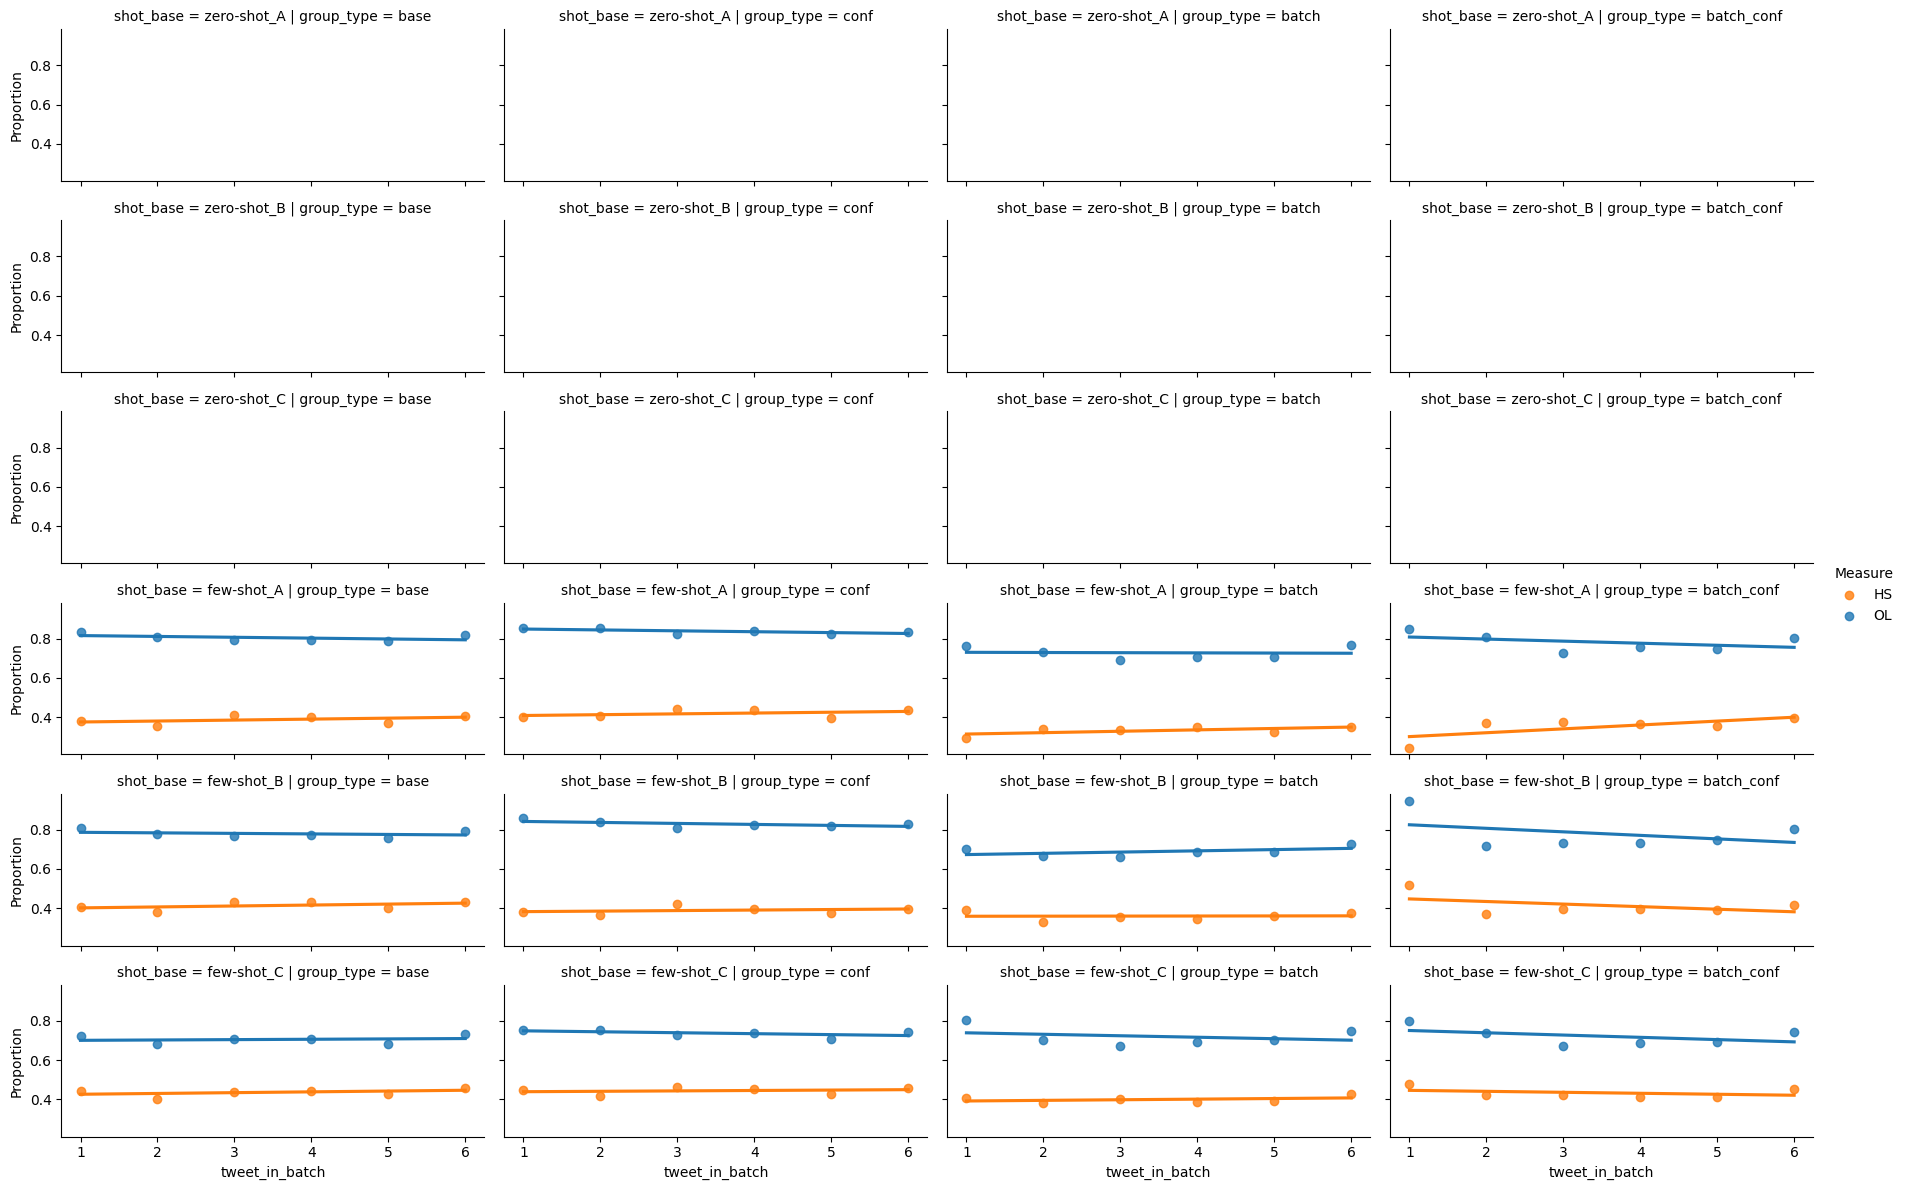

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.formula.api import mixedlm
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
import statsmodels.api as sm
import numpy as np
import warnings

# suppress convergence warnings (optional)
# warnings.filterwarnings('ignore')

# ---------------------------
# 1. Data Preparation
# ---------------------------

# 1a) Melt in the shot and batch_id columns
df_melt = df_long.melt(
    id_vars=['batch_id', 'condition', 'tweet_in_batch', 'shot'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Label'
)

# 1b) Filter out the “mismatched” C.* rows
mask = ~(
       (df_melt['condition'].str.contains(r'C\.OL')) & (df_melt['Measure'] == 'HS')
    |  (df_melt['condition'].str.contains(r'C\.HS')) & (df_melt['Measure'] == 'OL')
)
df_melt = df_melt[mask].reset_index(drop=True)

# 1c) Strip the “.OL” / “.HS” suffix so “C.OL_conf” → “C_conf”
df_melt['condition'] = df_melt['condition'].str.replace(r'\.OL|\.HS', '', regex=True)

# 1d) Extract group_type & base_condition, build shot_base
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    if x.endswith('_batch_conf'):
        return 'batch_conf'
    if x.endswith('_conf'):
        return 'conf'
    if x.endswith('_batch'):
        return 'batch'
    return 'other'

df_melt['group_type']     = df_melt['condition'].apply(extract_group_type)
df_melt['base_condition'] = df_melt['condition'].str.split('_').str[0]
df_melt['shot_base']      = df_melt['shot'] + '_' + df_melt['base_condition']

# 1e) Set categorical ordering for facets
df_melt['group_type'] = pd.Categorical(
    df_melt['group_type'],
    categories=['base','conf','batch','batch_conf'],
    ordered=True
)
row_order = (
    [f'zero-shot_{c}' for c in ['A','B','C']]
  + [f'few-shot_{c}'  for c in ['A','B','C']]
)
df_melt['shot_base'] = pd.Categorical(
    df_melt['shot_base'],
    categories=row_order,
    ordered=True
)

# ---------------------------
# 2. Compute proportions (for plotting)
# ---------------------------
df_prop = (
    df_melt
      .groupby(['shot','condition','tweet_in_batch','Measure'], as_index=False)
      ['Label']
      .mean()
      .rename(columns={'Label':'Proportion'})
)

# re‐derive the same facet columns on df_prop
df_prop['group_type']     = df_prop['condition'].apply(extract_group_type)
df_prop['base_condition'] = df_prop['condition'].str.split('_').str[0]
df_prop['shot_base']      = df_prop['shot'] + '_' + df_prop['base_condition']
df_prop['group_type'] = pd.Categorical(
    df_prop['group_type'],
    categories=['base','conf','batch','batch_conf'],
    ordered=True
)
df_prop['shot_base'] = pd.Categorical(
    df_prop['shot_base'],
    categories=row_order,
    ordered=True
)

# ---------------------------
# 3. Draw the lmplot (OLS lines)
# ---------------------------
palette = {'OL':'#1f77b4','HS':'#ff7f0e'}
g = sns.lmplot(
    data=df_prop,
    x='tweet_in_batch',
    y='Proportion',
    hue='Measure',
    col='group_type',
    row='shot_base',
    markers='o',
    ci=None,
    height=2,
    aspect=2.3,
    order=1,
    palette=palette
)

# ---------------------------
# 4. Fit mixed‐effects models for p‐values
#    (Label ~ tweet_in_batch + (1 | batch_id))
# ---------------------------
# pvals = {}
# for (shot_base, grp, meas), sub in df_melt.groupby(
#         ['shot_base','group_type','Measure'], observed=True):
#     md  = mixedlm("Label ~ tweet_in_batch", sub, groups=sub["batch_id"])
#     mdf = md.fit(reml=False)
#     pvals[(shot_base, grp, meas)] = mdf.pvalues["tweet_in_batch"]
    
    
pvals = {}
for key, sub in df_melt.groupby(['shot_base','group_type','Measure'], observed=True):

    # At least 2 batches and some predictor variation?
    if sub['batch_id'].nunique() < 2 or sub['tweet_in_batch'].nunique() < 2:
        pvals[key] = np.nan          # skip ›› non-significant
        continue

    # centre the predictor for numerical stability
    sub = sub.copy()
    sub['tweet_c'] = sub['tweet_in_batch'] - sub['tweet_in_batch'].mean()

    # random intercept: one dummy column per batch
    vc = {'batch': '0 + C(batch_id)'}
    model = BinomialBayesMixedGLM.from_formula(
        'Label ~ tweet_c', vc, data=sub
    )

    fit = model.fit_vb()             # or .fit_map() for Laplace-MAP
    pvals[key] = fit.pvalues['tweet_c']

# ---------------------------
# 5. Shade significant panels
# ---------------------------
for i, shot_base in enumerate(df_prop['shot_base'].cat.categories):
    for j, grp in enumerate(df_prop['group_type'].cat.categories):
        sig = any(
            pvals.get((shot_base, grp, meas), 1.0) < 0.05
            for meas in ['OL','HS']
        )
        if sig:
            ax = g.axes[i, j]
            ax.set_facecolor('lightgrey')

# ---------------------------
# 6. Annotate significance asterisks
# ---------------------------
for i, shot_base in enumerate(df_prop['shot_base'].cat.categories):
    for j, grp in enumerate(df_prop['group_type'].cat.categories):
        ax = g.axes[i, j]
        for k, meas in enumerate(['OL','HS']):
            p = pvals.get((shot_base, grp, meas), 1.0)
            if p < 0.5:
                y = 0.90 - k * 0.08  # adjust to stack OL/HS
                ax.text(
                    0.95, y, '*',
                    transform=ax.transAxes,
                    ha='right', va='center',
                    color=palette[meas],
                    fontsize=22,
                    fontweight='bold'
                )

# ---------------------------
# 7. Final labels & layout
# ---------------------------
g.set_axis_labels("Tweet Position in Batch", "Proportion")
g.fig.subplots_adjust(top=0.92, hspace=0.3)
g.fig.suptitle(
    "Effect of Position on OL/HS Proportions\n"
    "(asterisks = mixed‐model slope p<0.05; random intercept = batch_id)",
    fontsize=14
)

plt.show()


In [14]:
df_melt

,batch_id,condition,tweet_in_batch,shot,Measure,Label,group_type,base_condition,shot_base
0,1,A_conf,1,few-shot,OL,1,conf,A,few-shot_A
1,1,B_conf,1,few-shot,OL,1,conf,B,few-shot_B
2,1,C_conf,1,few-shot,OL,1,conf,C,few-shot_C
3,1,A,1,few-shot,OL,1,base,A,few-shot_A
4,1,B,1,few-shot,OL,1,base,B,few-shot_B
...,...,...,...,...,...,...,...,...,...
207343,500,B_batch_conf,6,few-shot,HS,0,batch_conf,B,few-shot_B
207344,500,C_batch_conf,6,few-shot,HS,0,batch_conf,C,few-shot_C
207345,500,A_batch,6,few-shot,HS,0,batch,A,few-shot_A
207346,500,B_batch,6,few-shot,HS,0,batch,B,few-shot_B
